# CausalSAE — Чекпойнт 2. Разведочный анализ данных

В проекте мы управляем поведением LLM через признаки SAE (steering) и смотрим, как это работает в гибридной модели, где слои linear attention чередуются с обычным attention. Подробнее о постановке — в `docs/niche_review.md`.

**Что анализируем.** Данные у нас двух видов:
1. Тексты с целевым свойством. Начинаем с тональности на SST-2: датасет хорошо размечен, предложения короткие, их дёшево прогонять через модель. Второе свойство (тема текста) добавим на ЧП3.
2. Внутренние представления модели на этих текстах: residual stream и признаки SAE. На них потом строится steering.

**Модель.** `Qwen/Qwen3.5-2B-Base` — 24 слоя, на каждые три слоя linear attention (Gated DeltaNet) приходится один слой full attention. SAE — официальные Qwen-Scope (`Qwen/SAE-Res-Qwen3.5-2B-Base-W32K-L0_50`): TopK, 32 768 признаков, 50 активных на токен, есть для всех слоёв.

Почему не Gemma-2 с Gemma Scope, как было в исходном плане: Gemma-2 — обычный трансформер, и для него основные вопросы по SAE-steering уже разобраны. Qwen3.5 — гибридная модель, для неё это почти не изучено, а SAE выпустили сами разработчики. Модель на 2B помещается на ноутбук (Apple M4 Pro, 48 ГБ).

**План ноутбука:**
1. Сплиты и баланс классов
2. Качество данных
3. Длины, выбросы, словарь
4. Рабочая выборка и проверка на утечки
5. Бейзлайны: TF-IDF и линейные пробы по слоям модели
6. Признаки SAE
7. Аугментации
8. Сводная таблица и выводы

In [1]:
import os, re, random, gc, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, datasets
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL = "Qwen/Qwen3.5-2B-Base"
SAE_REPO = "Qwen/SAE-Res-Qwen3.5-2B-Base-W32K-L0_50"
SAE_LAYERS = [6, 11, 16, 21]      # ~25/45/65/90% глубины
N_PER_CLASS = 1000                # размер train-пула на класс
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
print(DEVICE, torch.__version__)

mps 2.15.0


## 1. Данные: сплиты и баланс классов

In [2]:
ds = datasets.load_dataset("stanfordnlp/sst2")
tr, va, te = (ds[s].to_pandas() for s in ["train", "validation", "test"])
print({k: len(v) for k, v in [("train", tr), ("validation", va), ("test", te)]})
print("метки test:", te.label.unique())
display(tr.sample(8, random_state=SEED))

{'train': 67349, 'validation': 872, 'test': 1821}
метки test: [-1]


,idx,sentence,label
43787,43787,very pleasing at its best moments,1
16159,16159,", american chai is enough to make you put away the guitar , sell the amp , and apply to medical school .",0
59015,59015,too much like an infomercial for ram dass 's latest book aimed at the boomer,0
5108,5108,a stirring visual sequence,1
67052,67052,cool visual backmasking,1
35938,35938,hard ground,0
49879,49879,"the striking , quietly vulnerable personality of ms. ambrose",1
51591,51591,"pan nalin 's exposition is beautiful and mysterious , and",1


У `test` нет меток (это скрытый тест GLUE), поэтому тестом у нас будет `validation` — 872 полных предложения. Всё остальное берём из `train`.

Особенность SST-2: `train` — это не предложения, а все фразы из деревьев разбора 8 544 предложений. Поэтому там много обрывков вроде `"hard ground"` и отдельных слов.

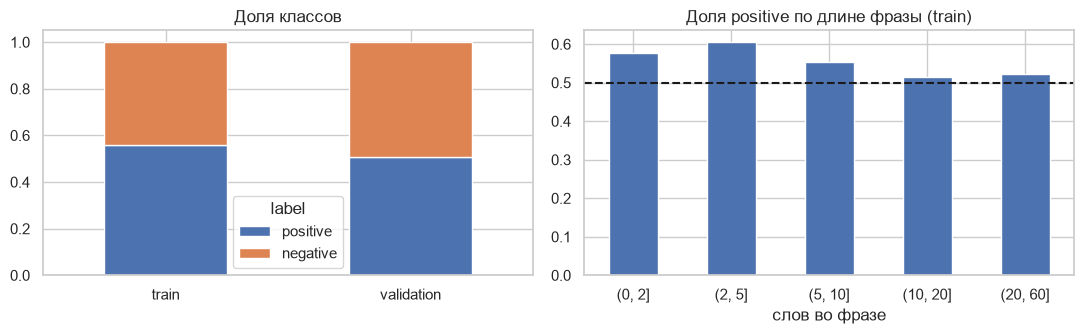

           mean   size
n_words               
(0, 2]    0.577  11511
(2, 5]    0.605  17120
(5, 10]   0.552  16130
(10, 20]  0.513  15216
(20, 60]  0.522   7372


In [3]:
for df in (tr, va):
    df["n_words"] = df.sentence.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pd.DataFrame({"train": tr.label.value_counts(normalize=True), "validation": va.label.value_counts(normalize=True)}) \
  .rename(index={0: "negative", 1: "positive"}).T.plot.bar(stacked=True, ax=ax[0], rot=0, title="Доля классов")
b = pd.cut(tr.n_words, [0, 2, 5, 10, 20, 60])
tr.groupby(b, observed=True).label.mean().plot.bar(ax=ax[1], rot=0, title="Доля positive по длине фразы (train)")
ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_xlabel("слов во фразе")
plt.tight_layout(); plt.show()
print(tr.groupby(b, observed=True).label.agg(["mean", "size"]).round(3))

В train 55.8% позитивных примеров, в validation примерно поровну. Перекос дают короткие фразы (среди фраз из 2–5 слов позитивных 60%), полные предложения сбалансированы. Для поиска признаков нам нужна ровная выборка, поэтому в разделе 4 балансируем её вручную.

## 2. Качество данных

In [4]:
s = tr.sentence.str.strip()
conf = tr.assign(s=s).groupby("s").label.nunique()
q = {
    "пустые строки": int((s == "").sum()),
    "точные дубликаты": int(s.duplicated().sum()),
    "одна фраза с разными метками": int((conf > 1).sum()),
    "фразы из 1–2 слов": int((tr.n_words <= 2).sum()),
    "всё в нижнем регистре, доля": round(float((tr.sentence == tr.sentence.str.lower()).mean()), 3),
    "PTB-артефакты (-lrb-, ` n't`, ` 's`), доля": round(float(tr.sentence.str.contains(r"-lrb-|-rrb-| n't| 's").mean()), 3),
    "validation ∩ train (точное совпадение)": int(va.sentence.str.strip().isin(set(s)).sum()),
}
display(pd.Series(q, name="значение").to_frame())
print("Конфликтующие метки:"); display(tr.assign(s=s)[s.isin(conf[conf > 1].index)].sort_values("s")[["sentence", "label"]])
print("Случайные 1–2-словные фразы:"); print(tr[tr.n_words <= 2].sample(12, random_state=1)[["sentence", "label"]].values.tolist())

,значение
пустые строки,0.000
точные дубликаты,371.000
одна фраза с разными метками,5.000
фразы из 1–2 слов,11511.000
"всё в нижнем регистре, доля",1.000
"PTB-артефакты (-lrb-, ` n't`, ` 's`), доля",0.129
validation ∩ train (точное совпадение),0.000


Конфликтующие метки:


,sentence,label
10928,excruciatingly,0
30663,excruciatingly,1
1433,laughably,0
54844,laughably,1
38764,sillier,0
42877,sillier,1
18521,sleeper,0
38655,sleeper,1
8493,the only reason,1
66327,the only reason,0


Случайные 1–2-словные фразы:
[['abysmally ', 0], ['old-fashioned-movie movie ', 1], ['fine-looking ', 1], ['enriched ', 1], ['strenuous ', 0], ['cruel story ', 0], ['engrossing entertainment ', 1], ['fire-breathing ', 1], ['10 ', 1], ['stunning fusion ', 1], ['ravishing waif ', 0], ['daring and ', 1]]


Пустых строк нет. Есть 371 дубликат (одинаковые фразы из разных деревьев) и 5 фраз с противоречивыми метками, их убираем.

17% train — фразы из 1–2 слов («10», «fire-breathing», «enriched»). Тональность у них часто неочевидна, и для модели это непривычный вход, поэтому для поиска признаков берём фразы от 8 слов.

Весь текст в нижнем регистре и разбит на токены в стиле Penn Treebank (`-lrb-`, `does n't`, ` , `). Модель и SAE обучались на обычном тексте, поэтому приводим текст к нормальному виду. Регистр восстанавливаем только у первой буквы. Насколько это важно, проверяем в разделе 7.

In [5]:
PTB = [(r"-lrb-", "("), (r"-rrb-", ")"), (r"``\s*", '"'), (r"\s*''", '"'), (r"`\s*", "'"),
       (r"\s+(n't|'s|'re|'ve|'m|'ll|'d)\b", r"\1"), (r"\s+([,.!?;:%])", r"\1"),
       (r"\(\s+", "("), (r"\s+\)", ")"), (r"\$\s+", "$"), (r"\s{2,}", " ")]

def detok(x: str) -> str:
    x = x.strip()
    for a, b in PTB:
        x = re.sub(a, b, x)
    return x[:1].upper() + x[1:]

assert detok("it does n't work , -lrb- sadly -rrb- .") == "It doesn't work, (sadly)."
for x in tr.sentence.sample(4, random_state=3):
    print(repr(x), "->", repr(detok(x)))

'goofy ( if not entirely wholesome ) fun ' -> 'Goofy (if not entirely wholesome) fun'
'a buoyant romantic comedy ' -> 'A buoyant romantic comedy'
"that you enjoy more because you 're one of the lucky few who sought it out " -> "That you enjoy more because you're one of the lucky few who sought it out"
'by the sketchiest of captions ' -> 'By the sketchiest of captions'


## 3. Длины, выбросы и словарь классов

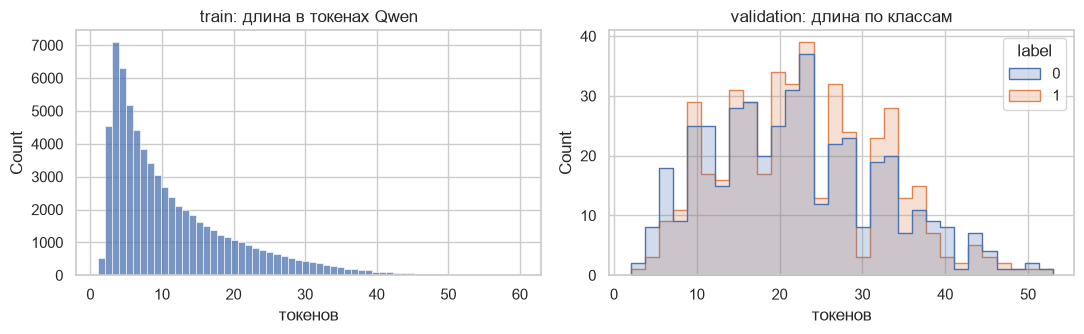

,count,mean,std,min,25%,50%,75%,max
train,67349.0,11.0,9.0,1.0,4.0,8.0,15.0,60.0
validation,872.0,22.2,9.9,2.0,14.0,22.0,29.0,53.0


validation: самые длинные / короткие:
["Stephen rea, aidan quinn, and alan bates play desmond's legal eagles, and when joined by brosnan, the sight of this grandiloquent quartet lolling in pretty irish settings is a pleasant enough thing, 'tis.", 'This is a train wreck of an action film -- a stupefying attempt by the filmmakers to force-feed james bond into the mindless xxx mold and throw 40 years of cinematic history down the toilet in favor of bright flashes and loud bangs.']
['Bad.', 'Cool?', 'Very bad.']


In [6]:
tok = AutoTokenizer.from_pretrained(MODEL)
for df in (tr, va):
    df["text"] = df.sentence.map(detok)
    df["n_tok"] = [len(t) for t in tok(df.text.tolist()).input_ids]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(tr.n_tok, bins=60, ax=ax[0]).set(title="train: длина в токенах Qwen", xlabel="токенов")
sns.histplot(data=va, x="n_tok", hue="label", bins=30, ax=ax[1], element="step").set(title="validation: длина по классам", xlabel="токенов")
plt.tight_layout(); plt.show()
display(pd.concat({"train": tr.n_tok.describe(), "validation": va.n_tok.describe()}, axis=1).round(1).T)
print("validation: самые длинные / короткие:")
print(va.nlargest(2, "n_tok").text.tolist()); print(va.nsmallest(3, "n_tok").text.tolist())

Тексты короткие: медиана 22 токена в validation, максимум 60, длинных выбросов нет. Длины у позитивных и негативных примеров распределены одинаково, так что по длине класс не угадать. Слишком короткие фрагменты мы уже отфильтровали.

Дальше смотрим, какие слова сильнее всего отличают классы (log-odds со сглаживанием).

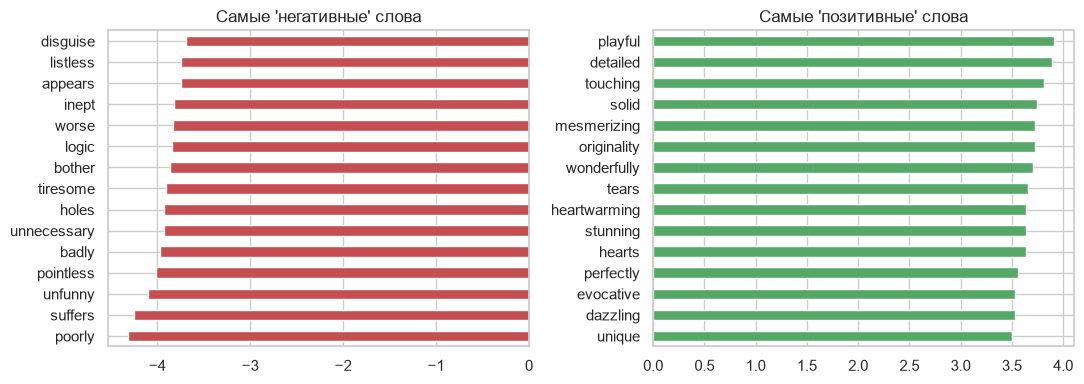

In [7]:
def words(t): return re.findall(r"[a-z']+", t.lower())
full = tr[tr.n_words >= 8]
cnt = {c: Counter(w for t in full.sentence[full.label == c] for w in words(t)) for c in (0, 1)}
vocab = [w for w in set(cnt[0]) | set(cnt[1]) if cnt[0][w] + cnt[1][w] >= 30]
n0, n1 = sum(cnt[0].values()), sum(cnt[1].values())
lo = pd.Series({w: np.log((cnt[1][w] + 1) / n1) - np.log((cnt[0][w] + 1) / n0) for w in vocab}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lo.head(15).plot.barh(ax=ax[0], color="C3", title="Самые 'негативные' слова")
lo.tail(15).plot.barh(ax=ax[1], color="C2", title="Самые 'позитивные' слова")
plt.tight_layout(); plt.show()

Слова ожидаемые: *poorly, suffers, unfunny, pointless* против *unique, dazzling, perfectly, stunning*. Есть и типичная лексика кинорецензий (*holes* и *logic* — «дыры в сюжете»). Тональность в SST-2 во многом определяется отдельными словами, поэтому простой bag-of-words будет сильным бейзлайном. Для нас это значит ещё и то, что признак SAE, найденный по разнице активаций, может просто реагировать на такие слова и при этом плохо управлять генерацией. Это проверим на ЧП3.

## 4. Рабочая выборка и проверка на утечки

Обучающая выборка: фразы из train длиной от 8 слов, без дубликатов и противоречий, сбалансированная по классам. Отдельно убираем вложенные фразы: иначе одно предложение попадает в выборку несколько раз своими кусками, и оценки получаются завышенными.

Тест — весь `validation`. Его не используем ни для выбора признаков, ни для выбора слоя или силы steering.

In [8]:
cand = tr.assign(s=s)[(tr.n_words >= 8) & ~s.duplicated(keep=False) & ~s.isin(conf[conf > 1].index)]
pool = cand.groupby("label").sample(n=2 * N_PER_CLASS, random_state=SEED)
pool = pool.assign(L=pool.s.str.len()).sort_values("L", ascending=False)
kept = []
for x in pool.s:                      # убираем фразы, вложенные в уже взятые (O(n^2) на ~4k строк)
    if not any(x in k for k in kept):
        kept.append(x)
pool = pool[pool.s.isin(set(kept))]
assert pool.label.value_counts().min() >= N_PER_CLASS
train_df = pool.groupby("label").sample(n=N_PER_CLASS, random_state=SEED).sample(frac=1, random_state=SEED)
test_df = va.copy()
print("кандидатов:", len(cand), "| после удаления вложенных:", len(kept), "| train-пул:", train_df.label.value_counts().to_dict(), "| test:", test_df.label.value_counts().to_dict())
tr_words = set(" ".join(train_df.s).split())
print("пересечение по 8-граммам train-пул ↔ test:",
      sum(any(" ".join(w[i:i+8]) in " ".join(train_df.s) for i in range(len(w) - 7)) for w in test_df.sentence.str.split()[:200]), "из 200 проверенных")
os.makedirs("data", exist_ok=True)
train_df[["idx", "text", "label"]].to_csv("data/sst2_train_pool.csv", index=False)
test_df[["idx", "text", "label"]].to_csv("data/sst2_test.csv", index=False)

кандидатов: 31105 | после удаления вложенных: 2919 | train-пул: {0: 1000, 1: 1000} | test: {1: 444, 0: 428}


пересечение по 8-граммам train-пул ↔ test: 0 из 200 проверенных


## 5. Бейзлайны

### 5.1 TF-IDF + логистическая регрессия
Самый простой бейзлайн, с ним сравниваем пробы по слоям модели.

In [9]:
results = []
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(C=10, max_iter=2000))
tfidf.fit(train_df.text, train_df.label)
results.append(("TF-IDF+LR, train-пул (2k)", accuracy_score(test_df.label, tfidf.predict(test_df.text))))
full_tr = tr.assign(s=s)[~s.duplicated() & ~s.isin(conf[conf > 1].index)]
tfidf_full = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(C=10, max_iter=2000)).fit(full_tr.text, full_tr.label)
results.append(("TF-IDF+LR, весь train (67k фраз)", accuracy_score(test_df.label, tfidf_full.predict(test_df.text))))
display(pd.DataFrame(results, columns=["модель", "test accuracy"]).round(3))

,модель,test accuracy
0,"TF-IDF+LR, train-пул (2k)",0.736
1,"TF-IDF+LR, весь train (67k фраз)",0.821


### 5.2 Линейные пробы по слоям Qwen3.5-2B

Прогоняем тексты через модель и забираем выход каждого из 24 слоёв хуками (`output_hidden_states` не подходит: последний элемент там уже после финальной нормализации). Текст представляем средним по токенам. Проба — логистическая регрессия на стандартизованных признаках: обучаем на рабочей выборке, проверяем на тесте.

In [10]:
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).to(DEVICE).eval()
layers = model.model.layers
N_LAYERS = len(layers)
LAYER_TYPES = model.config.layer_types
print(type(model).__name__, N_LAYERS, "слоёв; full attention:", [i for i, t in enumerate(LAYER_TYPES) if t == "full_attention"])

@torch.no_grad()
def residuals(texts, keep_layers, bs=32):
    # mean-pooled resid_post по всем слоям + потокенные активации для keep_layers
    pooled = np.zeros((len(texts), N_LAYERS, model.config.hidden_size), dtype=np.float32)
    per_tok = {l: [] for l in keep_layers}
    cap = {}
    hooks = [layers[i].register_forward_hook(lambda m, a, o, i=i: cap.__setitem__(i, o[0] if isinstance(o, tuple) else o)) for i in range(N_LAYERS)]
    try:
        for b in range(0, len(texts), bs):
            enc = tok(texts[b:b + bs], return_tensors="pt", padding=True).to(DEVICE)
            model(**enc)
            m = enc.attention_mask.unsqueeze(-1).float()
            for i in range(N_LAYERS):
                pooled[b:b + bs, i] = ((cap[i] * m).sum(1) / m.sum(1)).cpu().numpy()
            for l in keep_layers:
                per_tok[l] += [cap[l][j, enc.attention_mask[j].bool()].cpu() for j in range(len(enc.input_ids))]
    finally:
        for h in hooks: h.remove()
    return pooled, per_tok

tok.padding_side = "right"
t0 = time.time()
R_tr, T_tr = residuals(train_df.text.tolist(), SAE_LAYERS)
R_te, T_te = residuals(test_df.text.tolist(), SAE_LAYERS)
print(f"{time.time() - t0:.0f} c", R_tr.shape, R_te.shape)

Qwen3_5ForCausalLM 24 слоёв; full attention: [3, 7, 11, 15, 19, 23]


110 c (2000, 24, 2048) (872, 24, 2048)


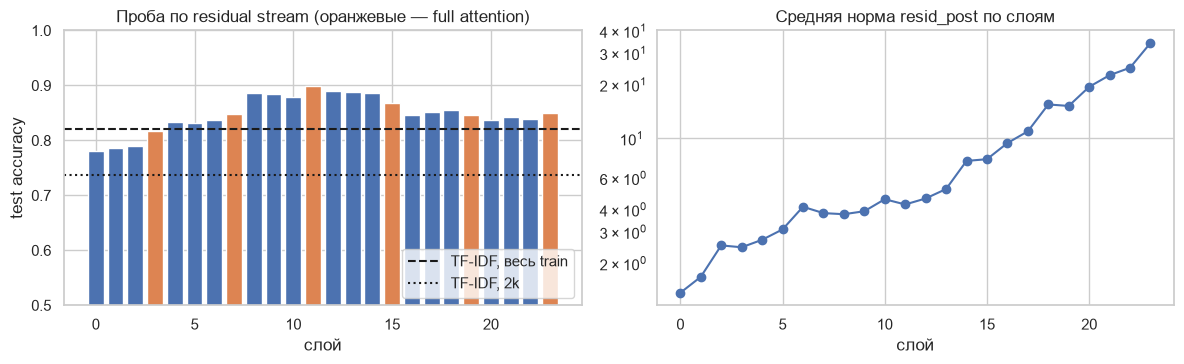

лучший слой: 11 acc = 0.899
acc на слоях SAE: {6: 0.837, 11: 0.899, 16: 0.846, 21: 0.842}


,mean,max,count
тип,,,
full_attention,0.855,0.899,6
linear_attention,0.847,0.890,18


по слоям: [0.78, 0.787, 0.79, 0.817, 0.833, 0.831, 0.837, 0.849, 0.886, 0.884, 0.88, 0.899, 0.89, 0.888, 0.886, 0.868, 0.846, 0.852, 0.856, 0.846, 0.837, 0.842, 0.838, 0.85]


In [11]:
y_tr, y_te = train_df.label.values, test_df.label.values
probe = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
acc = []
for i in range(N_LAYERS):
    p = probe().fit(R_tr[:, i], y_tr)
    acc.append(accuracy_score(y_te, p.predict(R_te[:, i])))
best_layer = int(np.argmax(acc))
norms = np.linalg.norm(R_tr, axis=2).mean(0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = ["C1" if t == "full_attention" else "C0" for t in LAYER_TYPES]
ax[0].bar(range(N_LAYERS), acc, color=cols); ax[0].set_ylim(0.5, 1)
ax[0].axhline(results[1][1], ls="--", c="k", label="TF-IDF, весь train"); ax[0].axhline(results[0][1], ls=":", c="k", label="TF-IDF, 2k")
ax[0].set(title="Проба по residual stream (оранжевые — full attention)", xlabel="слой", ylabel="test accuracy"); ax[0].legend(loc="lower right")
ax[1].plot(norms, marker="o"); ax[1].set(title="Средняя норма resid_post по слоям", xlabel="слой", yscale="log")
plt.tight_layout(); plt.show()
print("лучший слой:", best_layer, "acc =", round(acc[best_layer], 3)); print("acc на слоях SAE:", {l: round(acc[l], 3) for l in SAE_LAYERS})
results.append((f"Проба по residual, лучший слой {best_layer}", acc[best_layer]))
display(pd.DataFrame({"acc": acc, "тип": LAYER_TYPES}).groupby("тип").acc.agg(["mean", "max", "count"]).round(3))
print("по слоям:", [round(a, 3) for a in acc])

Проба показывает, на каких слоях тональность можно линейно прочитать из модели. Лучше всего — на средних слоях. Направление пробы и разность средних (DiffMean) потом пригодятся как простые направления для steering, с ними будем сравнивать признаки SAE. Норма активаций сильно растёт с глубиной, поэтому силу вмешательства придётся задавать отдельно для каждого слоя.

## 6. Признаки SAE (Qwen-Scope)

Для слоёв `SAE_LAYERS` кодируем активации через SAE и смотрим:
- насколько хорошо SAE восстанавливает наши активации (FVU — доля необъяснённой дисперсии);
- как часто срабатывают признаки и сколько из них на нашем корпусе не срабатывают вообще;
- какие признаки сильнее всего отличают позитив от негатива: по стандартизованной разности средних и по L1-логрегрессии.

In [12]:
def load_sae(layer):
    p = hf_hub_download(SAE_REPO, f"layer{layer}.sae.pt")
    w = torch.load(p, map_location=DEVICE)
    return {k: v.to(DEVICE, torch.float32) for k, v in w.items()}

@torch.no_grad()
def sae_encode(sae, x, k=50):
    pre = x @ sae["W_enc"].T + sae["b_enc"]
    v, i = pre.topk(k, dim=-1)
    return torch.zeros_like(pre).scatter_(-1, i, v)

@torch.no_grad()
def sae_stats(sae, toks):
    # mean-pooled коды по тексту, доля токенов с активностью признака, FVU
    D = sae["W_enc"].shape[0]
    pooled = np.zeros((len(toks), D), dtype=np.float32); fires = torch.zeros(D, device=DEVICE); n = 0; se = var = 0.0
    X_all = torch.cat(toks).to(DEVICE); mu = X_all.mean(0)
    for j, x in enumerate(toks):
        x = x.to(DEVICE); z = sae_encode(sae, x); xh = z @ sae["W_dec"].T + sae["b_dec"]
        pooled[j] = z.mean(0).cpu().numpy(); fires += (z > 0).sum(0); n += len(x)
        se += ((x - xh) ** 2).sum().item(); var += ((x - mu) ** 2).sum().item()
    return pooled, (fires / n).cpu().numpy(), se / var

SAE = {}
for l in SAE_LAYERS:
    sae = load_sae(l)
    Z_tr, f_tr, fvu_tr = sae_stats(sae, T_tr[l])
    Z_te, _, fvu_te = sae_stats(sae, T_te[l])
    SAE[l] = dict(Z_tr=Z_tr, Z_te=Z_te, freq=f_tr, fvu_tr=fvu_tr, fvu_te=fvu_te)
    del sae; gc.collect()
summary = pd.DataFrame({l: {"FVU train": d["fvu_tr"], "FVU test": d["fvu_te"], "мёртвых на корпусе, %": 100 * (d["freq"] == 0).mean(),
                            "частых (>10% токенов)": int((d["freq"] > 0.1).sum())} for l, d in SAE.items()}).T
display(summary.round(3))

,FVU train,FVU test,"мёртвых на корпусе, %",частых (>10% токенов)
6,0.149,0.158,37.598,28.0
11,0.268,0.273,39.279,24.0
16,0.253,0.256,36.896,34.0
21,0.294,0.297,36.795,42.0


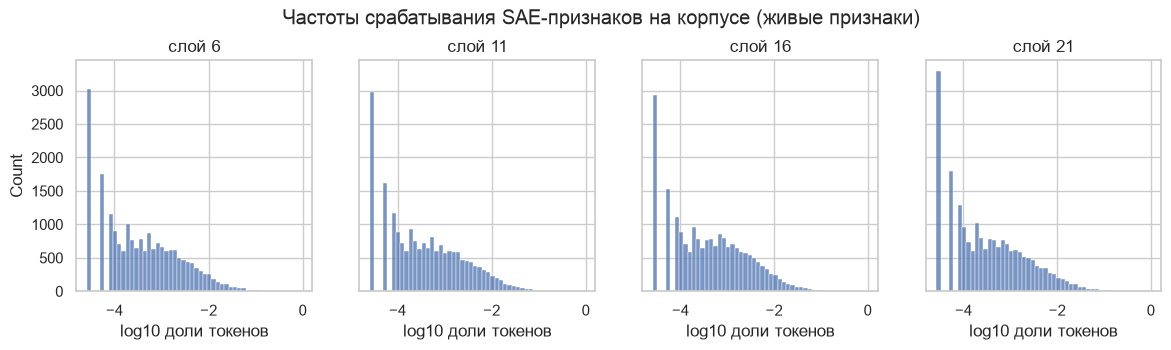

In [13]:
fig, axes = plt.subplots(1, len(SAE_LAYERS), figsize=(14, 3), sharey=True)
for ax, l in zip(axes, SAE_LAYERS):
    f = SAE[l]["freq"]; sns.histplot(np.log10(f[f > 0]), bins=50, ax=ax)
    ax.set(title=f"слой {l}", xlabel="log10 доли токенов")
plt.suptitle("Частоты срабатывания SAE-признаков на корпусе (живые признаки)", y=1.05); plt.show()

Много неактивных признаков — это нормально: SAE обучен на всём подряд (код, математика, разные языки), а у нас пара тысяч коротких отзывов о кино. Искать нужные признаки можно только среди тех, что срабатывают на нашем корпусе.

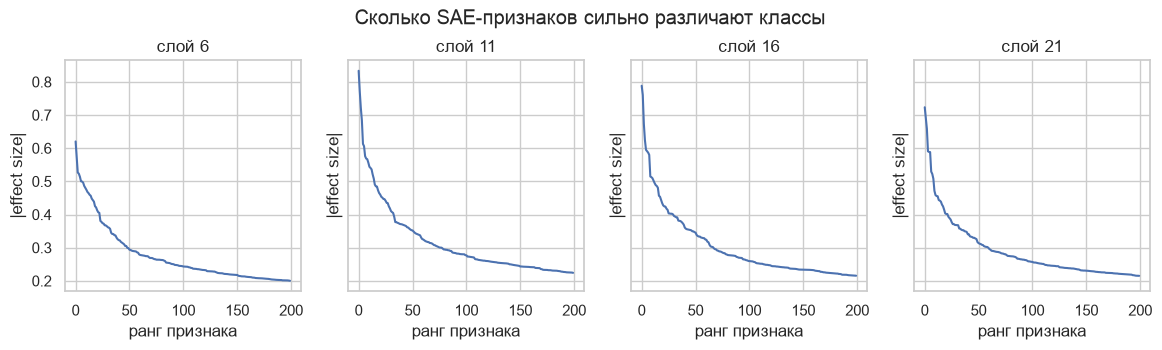

In [14]:
def effect_size(Z, y):
    a, b = Z[y == 1], Z[y == 0]
    return (a.mean(0) - b.mean(0)) / (np.sqrt((a.var(0) + b.var(0)) / 2) + 1e-6)

sel = {}
for l in SAE_LAYERS:
    d = SAE[l]; es = effect_size(d["Z_tr"], y_tr); d["es"] = es
    sel[l] = {"pos": np.argsort(-es)[:10], "neg": np.argsort(es)[:10]}
fig, axes = plt.subplots(1, len(SAE_LAYERS), figsize=(14, 3), sharey=True)
for ax, l in zip(axes, SAE_LAYERS):
    es = np.sort(np.abs(SAE[l]["es"]))[::-1][:200]; ax.plot(es); ax.set(title=f"слой {l}", xlabel="ранг признака", ylabel="|effect size|")
plt.suptitle("Сколько SAE-признаков сильно различают классы", y=1.05); plt.show()

Для лучшего слоя смотрим, на каких токенах срабатывают топ-признаки. Готовых описаний признаков Qwen-Scope в Neuronpedia нет, поэтому смотрим сами.

In [15]:
L = max(SAE_LAYERS, key=lambda l: acc[l])
sae = load_sae(L)
def top_tokens(fid, n=12):
    hits = []
    for j, x in enumerate(T_tr[L]):
        z = sae_encode(sae, x.to(DEVICE))[:, fid].cpu()
        if z.max() > 0:
            t = int(z.argmax()); ids = tok(train_df.text.iloc[j]).input_ids
            hits.append((float(z.max()), tok.decode(ids[t]), tok.decode(ids[max(0, t - 4):t + 2])))
    return sorted(hits, reverse=True)[:n]
rows = []
for side in ("pos", "neg"):
    for fid in sel[L][side][:4]:
        tt = top_tokens(fid)
        rows.append({"класс": side, "признак": int(fid), "effect size": round(float(SAE[L]["es"][fid]), 2),
                     "доля токенов": round(float(SAE[L]["freq"][fid]), 4),
                     "топ токены": ", ".join(Counter(t for _, t, _ in tt).most_common(6)[i][0].strip() for i in range(min(6, len(set(t for _, t, _ in tt))))),
                     "пример контекста": tt[0][2] if tt else ""})
print("слой", L); display(pd.DataFrame(rows))

слой 11


,класс,признак,effect size,доля токенов,топ токены,пример контекста
0,pos,25998,0.77,0.1339,"of, ,, invaluable, ., look, and",Provides an invaluable service
1,pos,22706,0.68,0.0736,"sequences, skills, ,, stunning, rival, executed",to some truly excellent sequences.
2,pos,10749,0.57,0.0324,"-rate, great, exceptional, distinguished, outstanding, sterling",-- despite some first-rate performances
3,pos,31691,0.56,0.0641,"., at, icle, ,, atory, study",", deeply humanizing."
4,neg,23501,-0.83,0.0878,"crap, idiots, reck, olt, garbage, foolish",see this piece of crap again
5,neg,12510,-0.72,0.0296,"short, pt, enjoyable, pp, useless, ly",both sides it falls short
6,neg,29252,-0.61,0.3191,"ried, arts, ula, ore, damage, sy",helping of re-fried green
7,neg,2503,-0.61,0.0110,"., ,",long and unfocused.


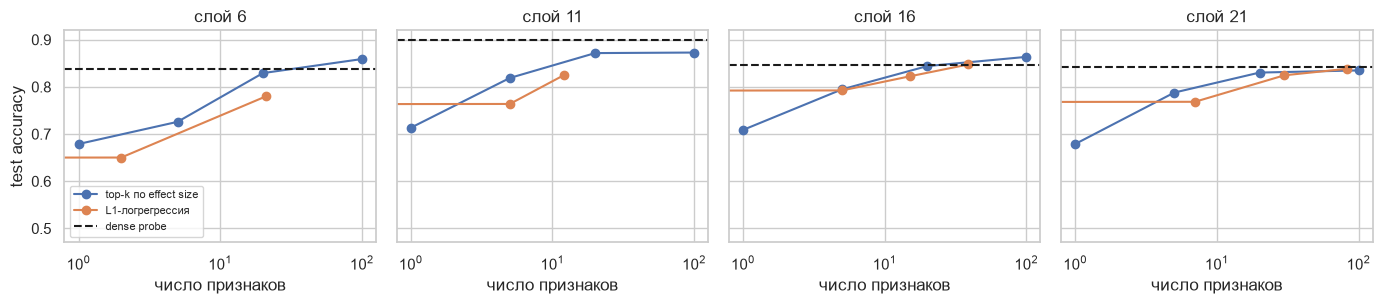

слой                          6      11     16     21
метод                k                               
L1-логрегрессия      0     0.491  0.491  0.491  0.491
                     2     0.650    NaN    NaN    NaN
                     5       NaN  0.764  0.792    NaN
                     7       NaN    NaN    NaN  0.768
                     12      NaN  0.825    NaN    NaN
                     15      NaN    NaN  0.822    NaN
                     21    0.780    NaN    NaN    NaN
                     30      NaN    NaN    NaN  0.825
                     39      NaN    NaN  0.847    NaN
                     83      NaN    NaN    NaN  0.838
dense residual probe 2048  0.837  0.899  0.846  0.842
top-k по effect size 1     0.679  0.713  0.709  0.679
                     5     0.726  0.819  0.795  0.788
                     20    0.829  0.872  0.844  0.830
                     100   0.859  0.873  0.864  0.835

слой 6: L1 (C=0.1) выбрала 2 признаков, пересечение с top-20 по effect size: 2
слой 11: L1 (C=0.1) выбрала 5 признаков, пересечение с top-20 по effect size: 5
слой 16: L1 (C=0.1) выбрала 15 признаков, пересечение с top-20 по effect size: 8
слой 21: L1 (C=0.1) выбрала 30 признаков, пересечение с top-20 по effect size: 14


In [16]:
rows = []
for l in SAE_LAYERS:
    Ztr, Zte = np.log1p(SAE[l]["Z_tr"]), np.log1p(SAE[l]["Z_te"])
    alive = SAE[l]["freq"] > 0
    for k in (1, 5, 20, 100):
        idx = np.argsort(-np.abs(SAE[l]["es"]))[:k]
        p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Ztr[:, idx], y_tr)
        rows.append({"слой": l, "метод": "top-k по effect size", "k": k, "acc": accuracy_score(y_te, p.predict(Zte[:, idx]))})
    for C in (0.01, 0.03, 0.1, 0.3):
        p = LogisticRegression(l1_ratio=1, C=C, solver="liblinear", max_iter=3000).fit(Ztr[:, alive], y_tr)
        nz = np.flatnonzero(p.coef_[0]); rows.append({"слой": l, "метод": "L1-логрегрессия", "k": len(nz), "acc": accuracy_score(y_te, p.predict(Zte[:, alive]))})
        if C == 0.1: SAE[l]["l1_sel"] = np.flatnonzero(alive)[nz]
    rows.append({"слой": l, "метод": "dense residual probe", "k": 2048, "acc": acc[l]})
sp = pd.DataFrame(rows)
fig, axes = plt.subplots(1, len(SAE_LAYERS), figsize=(14, 3.2), sharey=True)
for ax, l in zip(axes, SAE_LAYERS):
    g = sp[sp["слой"] == l]
    for m, c in [("top-k по effect size", "C0"), ("L1-логрегрессия", "C1")]:
        h = g[g["метод"] == m].sort_values("k"); ax.plot(h.k, h.acc, marker="o", c=c, label=m)
    ax.axhline(acc[l], ls="--", c="k", label="dense probe"); ax.set(xscale="log", title=f"слой {l}", xlabel="число признаков")
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(sp.pivot_table(index=["метод", "k"], columns="слой", values="acc").round(3))
best = sp[sp["метод"] != "dense residual probe"].sort_values("acc").iloc[-1]
results.append((f"SAE-проба, слой {int(best['слой'])}, {best['метод']}, k={int(best.k)}", best.acc))
for l in SAE_LAYERS:
    top20 = set(np.argsort(-np.abs(SAE[l]["es"]))[:20]); l1 = set(SAE[l]["l1_sel"])
    print(f"слой {l}: L1 (C=0.1) выбрала {len(l1)} признаков, пересечение с top-20 по effect size: {len(top20 & l1)}")

По графикам видно, сколько признаков SAE нужно, чтобы угадывать тональность почти так же хорошо, как проба по всему слою. Одного признака мало, нужно хотя бы 10–20. Ещё видно, совпадают ли признаки, выбранные разными способами.

Хорошо угадывать тональность ещё не значит хорошо ей управлять. Управление проверяем на ЧП3.

## 7. Аугментации

Здесь аугментации нужны в основном для проверки устойчивости: признак тональности должен срабатывать независимо от того, как записан текст.

| Аугментация | Метка сохраняется? | Зачем |
|---|---|---|
| Приведение PTB-текста к обычному виду | да | обязательно, это скорее исправление данных |
| Выпадение 15% слов | обычно да | проверка устойчивости |
| Перестановка соседних слов | да | то же, слабее |
| Обратный перевод, перефразирование | да, но надо проверять | дорого; может пригодиться для отдельной проверки |
| Шаблон вроде `Review: … Sentiment:` | да | понадобится для генерации |
| Замена на антонимы | нет, метка меняется | удобно для пар «позитив/негатив» |

Ниже проверяем первые три варианта на лучшем слое.

In [17]:
rng = random.Random(SEED)
def dropout(t, p=0.15): w = t.split(); return " ".join(x for x in w if rng.random() > p) or t
def swap(t): w = t.split(); i = rng.randrange(max(1, len(w) - 1)); w[i:i+2] = w[i:i+2][::-1]; return " ".join(w)
variants = {"детокенизированный (база)": test_df.text.tolist(), "исходный PTB-формат": test_df.sentence.tolist(),
            "word dropout 15%": [dropout(t) for t in test_df.text], "swap соседних слов": [swap(t) for t in test_df.text]}
dense_p = probe().fit(R_tr[:, L], y_tr)
top = np.argsort(-np.abs(SAE[L]["es"]))[:20]
sae_p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(np.log1p(SAE[L]["Z_tr"][:, top]), y_tr)
base_Z = None; rows = []
for name, texts in variants.items():
    Rv, Tv = residuals(texts, [L])
    Zv, _, fvu = sae_stats(sae, Tv[L])
    if base_Z is None: base_Z = Zv
    rows.append({"вариант": name, "dense acc": accuracy_score(y_te, dense_p.predict(Rv[:, L])),
                 "SAE top-20 acc": accuracy_score(y_te, sae_p.predict(np.log1p(Zv[:, top]))), "FVU SAE": fvu,
                 "корр. топ-признаков с базой": np.mean([np.corrcoef(base_Z[:, f], Zv[:, f])[0, 1] for f in top])})
display(pd.DataFrame(rows).round(3))

,вариант,dense acc,SAE top-20 acc,FVU SAE,корр. топ-признаков с базой
0,детокенизированный (база),0.899,0.872,0.273,1.000
1,исходный PTB-формат,0.885,0.852,0.293,0.913
2,word dropout 15%,0.856,0.834,0.268,0.853
3,swap соседних слов,0.885,0.849,0.276,0.909


## 8. Сводная таблица бейзлайнов

In [18]:
display(pd.DataFrame(results, columns=["модель", "test accuracy (SST-2 validation)"]).round(3))

,модель,test accuracy (SST-2 validation)
0,"TF-IDF+LR, train-пул (2k)",0.736
1,"TF-IDF+LR, весь train (67k фраз)",0.821
2,"Проба по residual, лучший слой 11",0.899
3,"SAE-проба, слой 11, top-k по effect size, k=100",0.873


## 9. Выводы

**Данные.** В SST-2 нет меток у test, поэтому тестом служит validation (872 предложения, классы примерно поровну). В train много мусора для нашей задачи: 17% обрывков из 1–2 слов, 371 дубликат, 5 противоречивых меток, текст в нижнем регистре и в PTB-токенизации. Мы привели текст к обычному виду, оставили фразы от 8 слов и сбалансировали выборку (1000/1000). Отдельно убрали вложенные фразы: среди 4 000 отобранных их оказалось 27%. Пересечений с тестом по 8-граммам нет.

**Бейзлайны.** TF-IDF с логрегрессией даёт 0.736 на нашей выборке и 0.821 на всём train. Линейная проба по слою 11 модели даёт 0.899, то есть по внутренним представлениям тональность угадывается лучше, чем по словам, даже на меньших данных. Лучше всего она читается на средних слоях (8–14), к концу точность падает до ~0.84. Тип слоя (linear или full attention) почти не влияет (0.847 против 0.855), важна глубина.

**SAE.** На наших данных SAE теряет 15% дисперсии на слое 6 и 27–30% на слоях 11–21. Возможно, поэтому проба по признакам SAE (0.873 на слое 11) немного уступает пробе по всему слою (0.899). 37–39% признаков на нашем корпусе не срабатывают ни разу. Среди активных есть понятные: на слое 11 признак #10749 реагирует на *first-rate, great, exceptional*, а #23501 на *crap, idiots, garbage*. Одного признака мало: с одним точность 0.68–0.71, с двадцатью 0.83–0.87. Чем глубже слой, тем больше признаков нужно (L1 выбирает 2, 5, 15 и 30 признаков на слоях 6, 11, 16 и 21).

**Аугментации.** Если подать текст в исходном PTB-виде, хуже становится и проба (0.899 → 0.885), и восстановление SAE, так что приводить текст к нормальному виду стоило. Сильнее всего на признаки влияет выпадение слов (точность падает до 0.856): признаки во многом держатся на ключевых оценочных словах.

**Дальше.** На ЧП3 используем эти слои и признаки для steering: сравним признаки SAE с DiffMean и посмотрим, через какую память модели (рекуррентное состояние или KV-кэш) проходит вмешательство и как быстро оно затухает при генерации. Направления и силу подбираем только на обучающей выборке, validation оставляем для финальной оценки.